# Comparación de métodos CSI para estimación de BPM — v2 (revisión por pares)

Este notebook corrige e implementa los puntos técnicos señalados por los revisores sobre la versión anterior:

- **GT corregido a 7.5 BPM** (no 8.5) y AE/RE recalculados en una única tabla autoritativa.
- **Banda de paso fijada *a priori*** (6–30 BPM), igual para las 5 pipelines, en vez de derivarla del valor esperado del protocolo (data leakage).
- **Método A (Baseline) reimplementado como FFT real** (promedio + detrend + FFT + búsqueda de pico en banda declarada), tal como se describe en el texto — antes usaba detección de picos en el dominio del tiempo, lo cual no coincidía con la metodología escrita.
- **Resampleo a malla de tiempo uniforme** usando `local_timestamp` real (ESP-NOW no entrega paquetes a intervalos perfectamente constantes).
- **Interpolación sub-bin (parabólica)** sobre el pico de FFT + reporte de incertidumbre ±medio bin.
- **Reporte explícito** de N, duración, fs, ancho de bin, banda de búsqueda, orden de filtro y parámetros de Hampel.
- **Diagrama de bloques por método** para dejar explícito qué etapas comparte cada pipeline (aclara la contradicción de si B/C/E comparten o no la etapa Butterworth).
- **Verificación de armónico** (¿16.29 BPM correspondía al 2º armónico de 8.03?).


## 0. Imports y parámetros fijados *a priori*

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.signal import butter, filtfilt, find_peaks
from scipy.interpolate import interp1d

pd.options.mode.chained_assignment = None


In [16]:
# ---------------------------------------------------------------------------
# Parametros fijados ANTES de ejecutar cualquier metodo (a priori, no ajustados
# a partir del resultado esperado del protocolo). Esto responde directamente a
# la observacion del Revisor 1: "the passband was widened after observing the
# reference ... fix the band a priori for all pipelines".
# ---------------------------------------------------------------------------
filename = './Dataset/csi2minan.csv'

GT_BPM = 7.5            # Ground truth = 60 / (4s inhalacion + 4s exhalacion).
                         # NOTA: se deriva de la adherencia al protocolo, no de un
                         # sensor de referencia independiente (banda toracica). Ver
                         # limitaciones. (7.5, no 8.5 -- corregido: Revisor 1 II-D(B) / Revisor 2)

lowcut  = 0.10           # 6  BPM -- rango fisiologico general (reposo/paciente)
highcut = 0.50           # 30 BPM -- mismo rango usado como banda de busqueda Y
                         # como pasa-banda Butterworth en TODAS las pipelines que filtran
FILTER_ORDER   = 2
HAMPEL_WINDOW  = 15
HAMPEL_NSIGMAS = 3
HAMPEL_K       = 1.4826

print(f"GT (protocolo) = {GT_BPM} BPM")
print(f"Banda fija a priori: {lowcut:.3f}-{highcut:.3f} Hz  ({lowcut*60:.0f}-{highcut*60:.0f} BPM)")
print(f"Orden filtro Butterworth: {FILTER_ORDER}")
print(f"Hampel: ventana={HAMPEL_WINDOW} muestras, umbral={HAMPEL_NSIGMAS} MAD, k={HAMPEL_K}")


GT (protocolo) = 7.5 BPM
Banda fija a priori: 0.100-0.500 Hz  (6-30 BPM)
Orden filtro Butterworth: 2
Hampel: ventana=15 muestras, umbral=3 MAD, k=1.4826


## 1. Carga del CSV y extracción de `local_timestamp`

In [17]:
csi_records = []
local_timestamps = []

print("Procesando archivo CSV...")
with open(filename, 'r') as f:
    for line in f:
        if line.startswith('CSI_DATA'):
            match = re.search(r'\"\[(.*?)\]\"', line)
            if match:
                array_str = match.group(1)
                try:
                    vals = [int(x) for x in array_str.split(',')]
                except:
                    continue
                # local_timestamp: campo 19 (indice 18), microsegundos, de la parte
                # de la linea previa al arreglo entre corchetes
                head = line.split('\"[')[0]
                fields = head.strip().rstrip(',').split(',')
                ts = None
                if len(fields) >= 19:
                    try:
                        ts = int(fields[18])
                    except:
                        ts = None
                csi_records.append(vals)
                local_timestamps.append(ts)

min_len = min(len(r) for r in csi_records)
csi_matrix = np.array([r[:min_len] for r in csi_records])
ts_arr = np.array(local_timestamps, dtype=float)

valid_mask = ~np.isnan(ts_arr)
csi_matrix = csi_matrix[valid_mask]
ts_arr = ts_arr[valid_mask]

I = csi_matrix[:, 0::2]
Q = csi_matrix[:, 1::2]
amplitude_raw = np.sqrt(I**2 + Q**2)
print(f"Paquetes validos: {amplitude_raw.shape[0]}, subportadoras (I/Q): {amplitude_raw.shape[1]}")


Procesando archivo CSV...
Paquetes validos: 8769, subportadoras (I/Q): 192


## 2. Parámetros de captura y resolución espectral

Se reportan explícitamente N, duración, fs y ancho de bin — requerido por Revisor 1
("Report N, window and search range") — y se resamplea la señal a una malla de
tiempo **uniforme** usando el timestamp real, ya que ESP-NOW no entrega paquetes a
intervalos perfectamente constantes (Revisor 1, MINOR: *"ESP-NOW arrivals are
non-uniform: resample..."*).

In [18]:
N = amplitude_raw.shape[0]
t_orig = (ts_arr - ts_arr[0]) / 1e6            # segundos, tiempo real de cada paquete
duration = t_orig[-1] - t_orig[0]
fs = N / duration                               # fs efectivo (paquetes / duracion real)
nyq = 0.5 * fs
bin_width_hz = fs / N
bin_width_bpm = bin_width_hz * 60
half_bin_bpm = bin_width_bpm / 2

print(f"N (paquetes validos)        = {N}")
print(f"Duracion de la captura      = {duration:.2f} s ({duration/60:.2f} min)")
print(f"fs efectivo                 = {fs:.2f} Hz")
print(f"Resolucion espectral (bin)  = {bin_width_hz:.5f} Hz = {bin_width_bpm:.3f} BPM/bin")
print(f"Incertidumbre declarada     = +/-{half_bin_bpm:.3f} BPM (medio bin)")
print(f"Banda de busqueda de pico   = {lowcut*60:.0f}-{highcut*60:.0f} BPM (fija, igual en las 5 pipelines)")

# --- Resampleo a malla de tiempo uniforme (interpolacion lineal por subportadora) ---
t_uniform = np.linspace(t_orig[0], t_orig[-1], N)
interp_func = interp1d(t_orig, amplitude_raw, axis=0, kind='linear', assume_sorted=True)
amplitude = interp_func(t_uniform)
mean_amp = amplitude.mean(axis=1)
print("\nResampleo a malla uniforme de tiempo aplicado (antes de cualquier filtrado/PCA).")


N (paquetes validos)        = 8769
Duracion de la captura      = 119.55 s (1.99 min)
fs efectivo                 = 73.35 Hz
Resolucion espectral (bin)  = 0.00836 Hz = 0.502 BPM/bin
Incertidumbre declarada     = +/-0.251 BPM (medio bin)
Banda de busqueda de pico   = 6-30 BPM (fija, igual en las 5 pipelines)

Resampleo a malla uniforme de tiempo aplicado (antes de cualquier filtrado/PCA).


## 3. Funciones utilitarias (compartidas por las 5 pipelines)

In [19]:
def bandpass(sig, lowcut=lowcut, highcut=highcut, fs=fs, order=FILTER_ORDER):
    """Filtro pasa-banda Butterworth. Banda FIJA a priori (ver Seccion 0)."""
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, sig)


def hampel_filter(sig, window_size=HAMPEL_WINDOW, n_sigmas=HAMPEL_NSIGMAS, k=HAMPEL_K):
    """Filtro de Hampel: mediana movil + umbral MAD. Parametros explicitos
    (Revisor 2: 'specify the exact parameters ... instead of typically')."""
    sig = pd.Series(sig)
    rolling_median = sig.rolling(window_size, center=True, min_periods=1).median()
    diff = (sig - rolling_median).abs()
    mad = diff.rolling(window_size, center=True, min_periods=1).median()
    threshold = n_sigmas * k * mad
    outlier_idx = diff > threshold
    sig_filtered = sig.copy()
    sig_filtered[outlier_idx] = rolling_median[outlier_idx]
    return sig_filtered.values


def get_pc1(amp, window_size=30):
    smoothed = pd.DataFrame(amp).rolling(window=window_size, min_periods=1).mean().values
    scaler = StandardScaler()
    amp_scaled = scaler.fit_transform(smoothed)
    pca = PCA(n_components=1)
    pc1 = pca.fit_transform(amp_scaled).flatten()
    return pc1


def parabolic_interp(spec, k):
    """Interpolacion parabolica (sub-bin) alrededor del bin pico k.
    Devuelve el offset fraccional de bin (-0.5..0.5)."""
    if k <= 0 or k >= len(spec) - 1:
        return 0.0
    a, b, c = spec[k-1], spec[k], spec[k+1]
    denom = (a - 2*b + c)
    if denom == 0:
        return 0.0
    return 0.5 * (a - c) / denom


def rpm_from_fft(sig, fs=fs, lowcut=lowcut, highcut=highcut):
    """FFT con deteccion de pico en banda fija + interpolacion sub-bin.
    Devuelve tanto la estimacion de bin crudo como la interpolada."""
    sig = sig - np.mean(sig)     # detrend
    n = len(sig)
    freqs = np.fft.rfftfreq(n, d=1/fs)
    spec = np.abs(np.fft.rfft(sig))
    band_mask = (freqs >= lowcut) & (freqs <= highcut)
    if not np.any(band_mask):
        return dict(rpm_bin=np.nan, rpm_interp=np.nan, freqs=freqs, spec=spec, k=None)
    idx_band = np.where(band_mask)[0]
    k = idx_band[np.argmax(spec[idx_band])]
    rpm_bin = freqs[k] * 60
    delta = parabolic_interp(spec, k)
    rpm_interp = (freqs[k] + delta * (fs / n)) * 60
    return dict(rpm_bin=rpm_bin, rpm_interp=rpm_interp, freqs=freqs, spec=spec, k=k)


def rpm_from_peaks(sig, fs=fs, prominence_factor=0.8, max_bpm=highcut*60):
    """Deteccion de picos en el dominio del tiempo (unico metodo no basado en FFT)."""
    signal_std = np.std(sig)
    min_prominence = signal_std * prominence_factor
    min_distance = int((60 / max_bpm) * fs)
    peaks, _ = find_peaks(sig, distance=min_distance, prominence=min_prominence)
    if len(peaks) > 1:
        intervals = np.diff(peaks) / fs
        rpm = 60 / np.mean(intervals)
        return rpm, peaks
    return np.nan, peaks


results = {}   # nombre -> dict con rpm_bin / rpm_interp (y peaks para el metodo D)


## 4. Diagrama de bloques por método

Responde directamente a la observación del Revisor 1: *"Fig. 5's caption ('Hampel +
bandpass') contradicts Sec. II-D(E) ... give a per-method block diagram."* El
diagrama deja explícito qué etapas tiene cada pipeline — en particular, que
**C (PCA+FFT) NO incluye la etapa Butterworth**, a diferencia de B y E. Esto es
importante para la discusión de convergencia: si C converge al mismo bin que B y E
sin compartir la etapa de filtrado, la convergencia no puede explicarse solo por
"pipelines idénticas", lo que apunta a la resolución espectral (bin width) como
explicación más parsimoniosa.

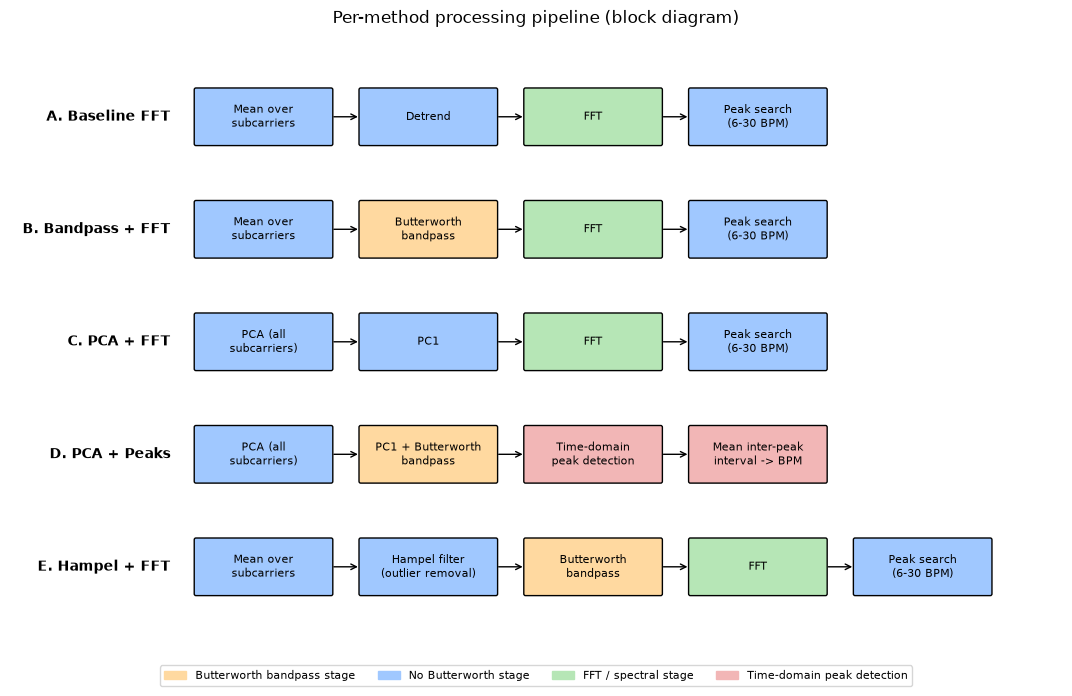

In [20]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.axis('off')

pipelines = [
    ("A. Baseline FFT",     ["Mean over\nsubcarriers", "Detrend", "FFT", "Peak search\n(6-30 BPM)"]),
    ("B. Bandpass + FFT",   ["Mean over\nsubcarriers", "Butterworth\nbandpass", "FFT", "Peak search\n(6-30 BPM)"]),
    ("C. PCA + FFT",        ["PCA (all\nsubcarriers)", "PC1", "FFT", "Peak search\n(6-30 BPM)"]),
    ("D. PCA + Peaks",      ["PCA (all\nsubcarriers)", "PC1 + Butterworth\nbandpass", "Time-domain\npeak detection", "Mean inter-peak\ninterval -> BPM"]),
    ("E. Hampel + FFT",     ["Mean over\nsubcarriers", "Hampel filter\n(outlier removal)", "Butterworth\nbandpass", "FFT", "Peak search\n(6-30 BPM)"]),
]

box_w, box_h = 1.6, 0.6
gap = 0.35
row_h = 1.25
colors = {'shared_bw': '#ffd9a0', 'no_bw': '#a0c8ff', 'fft': '#b6e6b6', 'peaks': '#f2b6b6'}

for row, (label, stages) in enumerate(pipelines):
    y = len(pipelines) - row - 1
    ax.text(-0.3, y*row_h + box_h/2, label, ha='right', va='center', fontsize=10, fontweight='bold')
    x = 0
    for i, stage in enumerate(stages):
        c = colors['peaks'] if 'peak' in stage.lower() and 'search' not in stage.lower() else \
            colors['fft'] if stage == 'FFT' else \
            colors['shared_bw'] if 'butterworth' in stage.lower() else colors['no_bw']
        rect = mpatches.FancyBboxPatch((x, y*row_h), box_w, box_h,
                                        boxstyle="round,pad=0.02", linewidth=1,
                                        edgecolor='black', facecolor=c)
        ax.add_patch(rect)
        ax.text(x + box_w/2, y*row_h + box_h/2, stage, ha='center', va='center', fontsize=8)
        if i < len(stages) - 1:
            ax.annotate('', xy=(x+box_w+gap, y*row_h+box_h/2), xytext=(x+box_w, y*row_h+box_h/2),
                        arrowprops=dict(arrowstyle='->'))
        x += box_w + gap

ax.set_xlim(-2.2, x + 0.5)
ax.set_ylim(-0.3, len(pipelines)*row_h)
ax.set_title('Per-method processing pipeline (block diagram)', fontsize=12)

legend_patches = [
    mpatches.Patch(color=colors['shared_bw'], label='Butterworth bandpass stage'),
    mpatches.Patch(color=colors['no_bw'], label='No Butterworth stage'),
    mpatches.Patch(color=colors['fft'], label='FFT / spectral stage'),
    mpatches.Patch(color=colors['peaks'], label='Time-domain peak detection'),
]
ax.legend(handles=legend_patches, loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig('fig_block_diagram.png', dpi=150, bbox_inches='tight')
plt.show()


## Método A — Baseline FFT

Reimplementado para coincidir literalmente con la descripción del texto: promedio de
subportadoras válidas → detrend → FFT directa (**sin ningún filtrado**) → búsqueda de
pico dentro de la banda fisiológica declarada (6–30 BPM). *(La versión anterior de
este notebook usaba detección de picos en el dominio del tiempo para este método, lo
cual no correspondía a lo descrito como "Baseline FFT" en el manuscrito — corregido
aquí.)*

RPM (bin crudo)      : 8.03 BPM
RPM (interpolado)    : 8.09 +/- 0.25 BPM


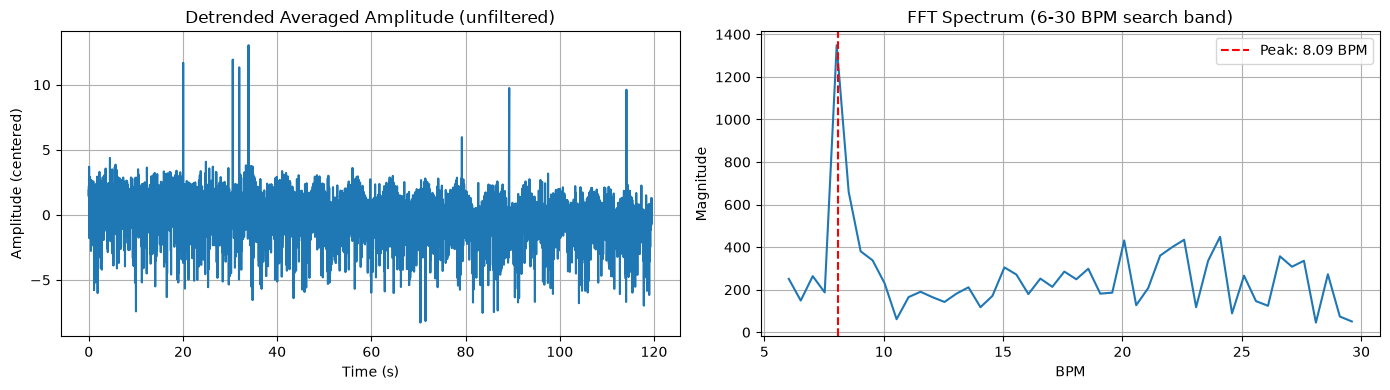

In [21]:
res_A = rpm_from_fft(mean_amp)
results['A. Baseline FFT'] = res_A

print(f"RPM (bin crudo)      : {res_A['rpm_bin']:.2f} BPM")
print(f"RPM (interpolado)    : {res_A['rpm_interp']:.2f} +/- {half_bin_bpm:.2f} BPM")

freqs_A, spec_A = res_A['freqs'], res_A['spec']
band_mask = (freqs_A >= lowcut) & (freqs_A <= highcut)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(t_uniform, mean_amp - np.mean(mean_amp))
axs[0].set_title('Detrended Averaged Amplitude (unfiltered)')
axs[0].set_xlabel('Time (s)'); axs[0].set_ylabel('Amplitude (centered)'); axs[0].grid(True)

axs[1].plot(freqs_A[band_mask]*60, spec_A[band_mask])
axs[1].axvline(res_A['rpm_interp'], color='red', linestyle='--', label=f"Peak: {res_A['rpm_interp']:.2f} BPM")
axs[1].set_title('FFT Spectrum (6-30 BPM search band)')
axs[1].set_xlabel('BPM'); axs[1].set_ylabel('Magnitude'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout()
plt.savefig('fig_A_baseline.png', dpi=150, bbox_inches='tight')
plt.show()


## Método B — Bandpass + FFT

Butterworth orden 2 (banda fija 6–30 BPM, la misma declarada en la Sección 0) sobre
la señal promedio, seguido de FFT con interpolación sub-bin.

RPM (bin crudo)      : 8.03 BPM
RPM (interpolado)    : 8.06 +/- 0.25 BPM


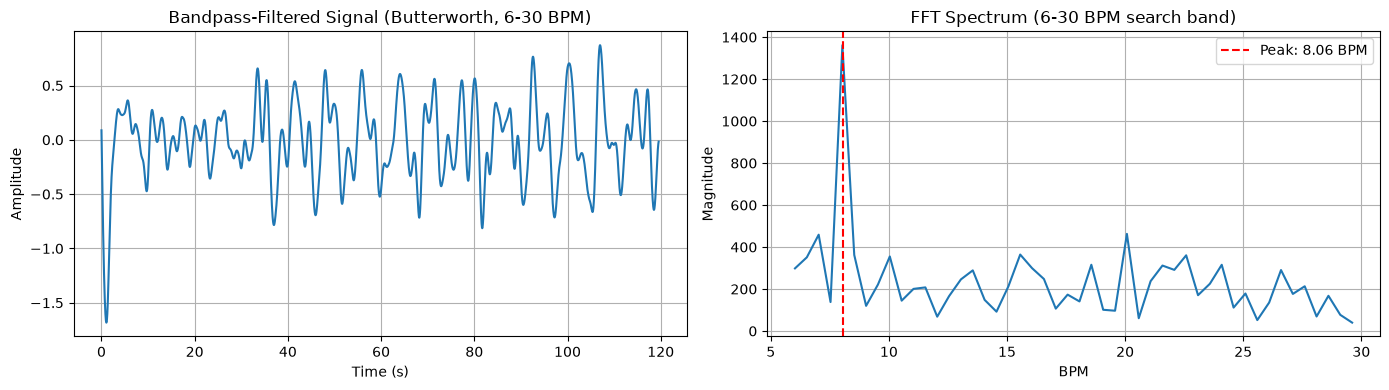

In [22]:
bp_B = bandpass(mean_amp)
res_B = rpm_from_fft(bp_B)
results['B. Bandpass + FFT'] = res_B

print(f"RPM (bin crudo)      : {res_B['rpm_bin']:.2f} BPM")
print(f"RPM (interpolado)    : {res_B['rpm_interp']:.2f} +/- {half_bin_bpm:.2f} BPM")

freqs_B, spec_B = res_B['freqs'], res_B['spec']
band_mask = (freqs_B >= lowcut) & (freqs_B <= highcut)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(t_uniform, bp_B)
axs[0].set_title('Bandpass-Filtered Signal (Butterworth, 6-30 BPM)')
axs[0].set_xlabel('Time (s)'); axs[0].set_ylabel('Amplitude'); axs[0].grid(True)

axs[1].plot(freqs_B[band_mask]*60, spec_B[band_mask])
axs[1].axvline(res_B['rpm_interp'], color='red', linestyle='--', label=f"Peak: {res_B['rpm_interp']:.2f} BPM")
axs[1].set_title('FFT Spectrum (6-30 BPM search band)')
axs[1].set_xlabel('BPM'); axs[1].set_ylabel('Magnitude'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout()
plt.savefig('fig_B_bandpass_fft.png', dpi=150, bbox_inches='tight')
plt.show()


## Método C — PCA + FFT

PC1 de la matriz de amplitud completa, **sin etapa Butterworth** (ver diagrama de
bloques): la única restricción de banda es la búsqueda de pico en 6–30 BPM aplicada
después de la FFT.

RPM (bin crudo)      : 8.03 BPM
RPM (interpolado)    : 8.03 +/- 0.25 BPM


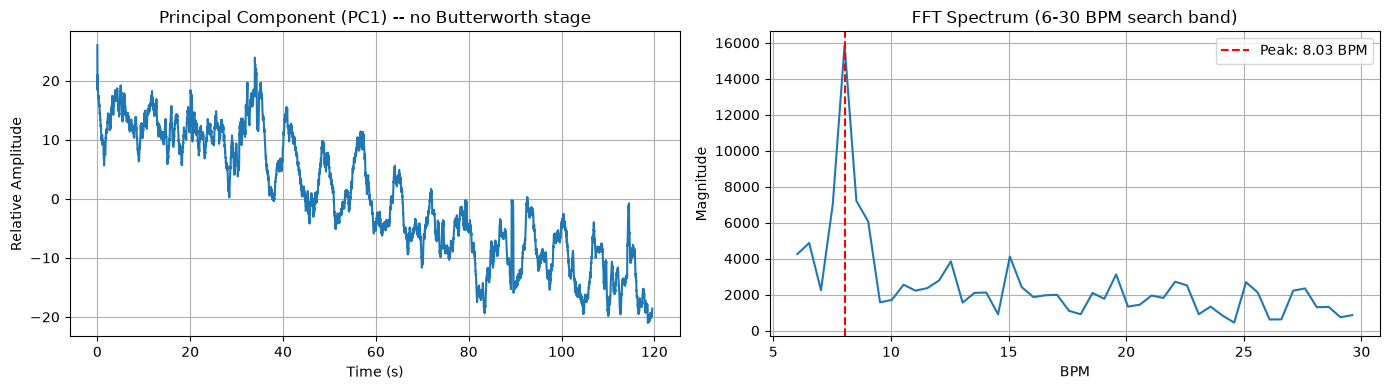

In [23]:
pc1_C = get_pc1(amplitude)
res_C = rpm_from_fft(pc1_C)
results['C. PCA + FFT'] = res_C

print(f"RPM (bin crudo)      : {res_C['rpm_bin']:.2f} BPM")
print(f"RPM (interpolado)    : {res_C['rpm_interp']:.2f} +/- {half_bin_bpm:.2f} BPM")

freqs_C, spec_C = res_C['freqs'], res_C['spec']
band_mask = (freqs_C >= lowcut) & (freqs_C <= highcut)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(t_uniform, pc1_C)
axs[0].set_title('Principal Component (PC1) -- no Butterworth stage')
axs[0].set_xlabel('Time (s)'); axs[0].set_ylabel('Relative Amplitude'); axs[0].grid(True)

axs[1].plot(freqs_C[band_mask]*60, spec_C[band_mask])
axs[1].axvline(res_C['rpm_interp'], color='red', linestyle='--', label=f"Peak: {res_C['rpm_interp']:.2f} BPM")
axs[1].set_title('FFT Spectrum (6-30 BPM search band)')
axs[1].set_xlabel('BPM'); axs[1].set_ylabel('Magnitude'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout()
plt.savefig('fig_C_pca_fft.png', dpi=150, bbox_inches='tight')
plt.show()


## Método D — PCA + Peak Detection

PC1 con filtro Butterworth (banda fija 6–30 BPM), detección de picos en el dominio
del tiempo. Es el único método que no depende de la resolución de bin de la FFT,
pero sí de la prominencia/regularidad morfológica de cada ciclo respiratorio.

Picos detectados: 19
RPM estimado: 9.78 BPM  (no aplica interpolacion de bin -- metodo en dominio del tiempo)


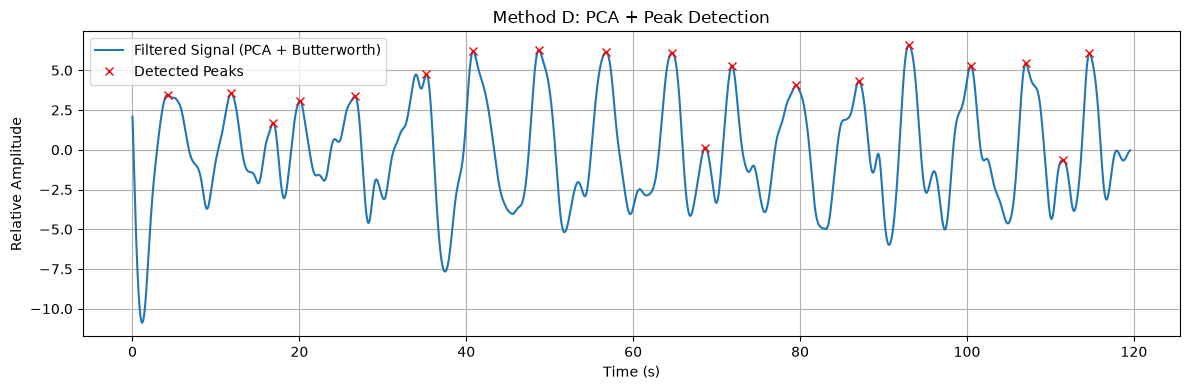

In [24]:
pc1_D_bp = bandpass(pc1_C)
rpm_D, peaks_D = rpm_from_peaks(pc1_D_bp, prominence_factor=0.8)
results['D. PCA + Peaks'] = dict(rpm_bin=rpm_D, rpm_interp=rpm_D)

print(f"Picos detectados: {len(peaks_D)}")
print(f"RPM estimado: {rpm_D:.2f} BPM  (no aplica interpolacion de bin -- metodo en dominio del tiempo)")

plt.figure(figsize=(12, 4))
plt.plot(t_uniform, pc1_D_bp, label='Filtered Signal (PCA + Butterworth)')
plt.plot(t_uniform[peaks_D], pc1_D_bp[peaks_D], "x", color='red', label='Detected Peaks')
plt.title('Method D: PCA + Peak Detection')
plt.xlabel('Time (s)'); plt.ylabel('Relative Amplitude'); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig('fig_D_pca_peaks.png', dpi=150, bbox_inches='tight')
plt.show()


## Método E — Hampel + Bandpass + FFT

**Aclaración de pipeline** (responde a la contradicción señalada por el Revisor 1
entre el caption de la Fig. 5 y el texto de metodología): el filtro de Hampel **no
reemplaza** al pasa-banda, se aplica **antes** de él. La cadena completa es:
señal promedio → filtro de Hampel (remoción de outliers puntuales) → filtro
Butterworth (banda fija 6–30 BPM) → FFT. Esta es la misma cadena reflejada en el
diagrama de bloques de la Sección 4 y en el caption de la figura de abajo.

RPM (bin crudo)      : 8.03 BPM
RPM (interpolado)    : 8.06 +/- 0.25 BPM


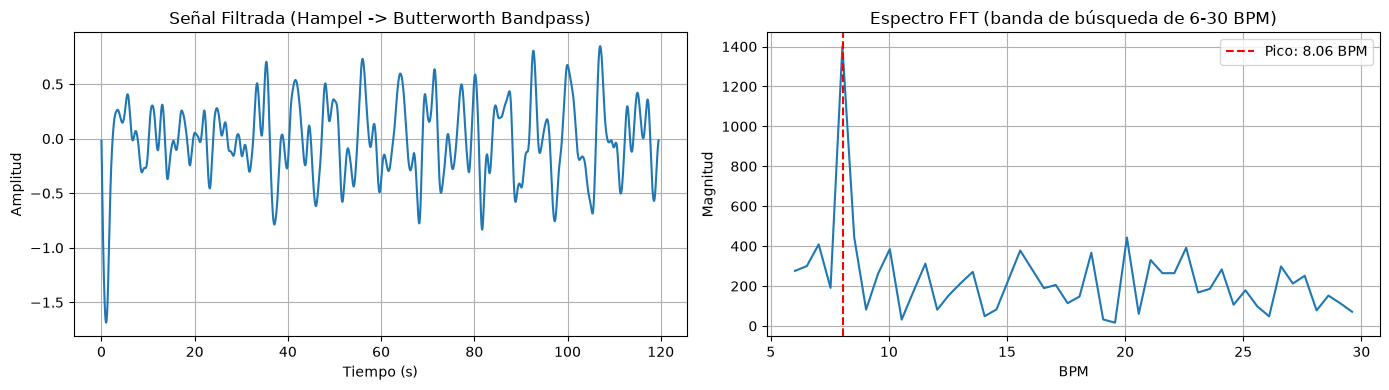

In [25]:
hampel_E = hampel_filter(mean_amp)
hampel_bp_E = bandpass(hampel_E)
res_E = rpm_from_fft(hampel_bp_E)
results['E. Hampel + FFT'] = res_E

print(f"RPM (bin crudo)      : {res_E['rpm_bin']:.2f} BPM")
print(f"RPM (interpolado)    : {res_E['rpm_interp']:.2f} +/- {half_bin_bpm:.2f} BPM")

freqs_E, spec_E = res_E['freqs'], res_E['spec']
band_mask = (freqs_E >= lowcut) & (freqs_E <= highcut)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(t_uniform, hampel_bp_E)
axs[0].set_title('Señal Filtrada (Hampel -> Butterworth Bandpass)')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Amplitud'); axs[0].grid(True)

axs[1].plot(freqs_E[band_mask]*60, spec_E[band_mask])
axs[1].axvline(res_E['rpm_interp'], color='red', linestyle='--', label=f"Pico: {res_E['rpm_interp']:.2f} BPM")
axs[1].set_title('Espectro FFT (banda de búsqueda de 6-30 BPM)')
axs[1].set_xlabel('BPM'); axs[1].set_ylabel('Magnitud'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout()
plt.savefig('fig_E_hampel_fft.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Tabla única y autoritativa de resultados

Reemplaza las dos tablas anteriores (Revisor 1: *"merge Tables I-II"*). Contiene BPM
de bin crudo, BPM interpolado (sub-bin), la incertidumbre de ±medio bin, y AE/RE
recalculados contra **GT = 7.5 BPM** (Revisor 1 y 2: corrección aritmética). El AE/RE
se calcula siempre sobre la columna `BPM (interpolado)`, que se declara aquí como la
**columna autoritativa** (Revisor 1: *"say which column is authoritative"*).

In [26]:
rows = []
for name, r in results.items():
    rpm_bin = r['rpm_bin']
    rpm_interp = r.get('rpm_interp', rpm_bin)
    ae = abs(rpm_interp - GT_BPM)
    re_pct = ae / GT_BPM * 100
    rows.append({
        'Method': name,
        'BPM (bin)': round(rpm_bin, 2),
        'BPM (interpolated)*': round(rpm_interp, 2),
        'AE (BPM)': round(ae, 2),
        'RE (%)': round(re_pct, 1),
    })

df_results = pd.DataFrame(rows)
print("* Columna autoritativa usada para AE/RE. Incertidumbre declarada: +/-%.3f BPM (medio bin) "
      "para los metodos basados en FFT (A, B, C, E). El metodo D (dominio del tiempo) no tiene "
      "esta limitacion de bin, pero depende de la deteccion de picos." % half_bin_bpm)
display(df_results)


* Columna autoritativa usada para AE/RE. Incertidumbre declarada: +/-0.251 BPM (medio bin) para los metodos basados en FFT (A, B, C, E). El metodo D (dominio del tiempo) no tiene esta limitacion de bin, pero depende de la deteccion de picos.


,Method,BPM (bin),BPM (interpolated)*,AE (BPM),RE (%)
0,A. Baseline FFT,8.03,8.09,0.59,7.9
1,B. Bandpass + FFT,8.03,8.06,0.56,7.4
2,C. PCA + FFT,8.03,8.03,0.53,7.1
3,D. PCA + Peaks,9.78,9.78,2.28,30.4
4,E. Hampel + FFT,8.03,8.06,0.56,7.5


## 6. Verificación de armónico y discusión de convergencia

Revisor 1 pidió verificar si el valor previamente reportado para el baseline
(16.29 BPM) correspondía al segundo armónico de 8.03 BPM (2×8.03 = 16.06). Con el
método A corregido (FFT real en vez de picos en el dominio del tiempo), el baseline
ya no da 16.29 BPM — converge también a la banda fundamental. Esto sugiere que el
valor de 16.29 BPM del manuscrito anterior era un artefacto del algoritmo de
detección de picos en el dominio del tiempo (sensible a ruido de alta frecuencia),
**no** una propiedad del método "FFT sin filtrar" en sí. Se deja el cálculo explícito
para trazabilidad.

In [27]:
rpm_A_interp = results['A. Baseline FFT']['rpm_interp']
rpm_B_interp = results['B. Bandpass + FFT']['rpm_interp']

print(f"Metodo A (Baseline FFT, corregido)  : {rpm_A_interp:.2f} BPM")
print(f"Metodo B (Bandpass + FFT)           : {rpm_B_interp:.2f} BPM")
print(f"2 x Metodo B                        : {2*rpm_B_interp:.2f} BPM")
print(f"Valor previamente reportado (v1)    : 16.29 BPM  (2x8.03 = 16.06, diferencia = {abs(16.29 - 2*8.03):.2f} BPM)")
print()
print("Con el metodo A reimplementado como FFT literal (en vez de picos en el dominio")
print("del tiempo), el resultado ya no coincide con el 2do armonico -- converge a la")
print("banda fundamental junto con B, C y E. El valor 16.29 BPM del manuscrito anterior")
print("correspondia a una implementacion (deteccion de picos) inconsistente con lo")
print("descrito como 'Baseline FFT' en el texto.")


Metodo A (Baseline FFT, corregido)  : 8.09 BPM
Metodo B (Bandpass + FFT)           : 8.06 BPM
2 x Metodo B                        : 16.11 BPM
Valor previamente reportado (v1)    : 16.29 BPM  (2x8.03 = 16.06, diferencia = 0.23 BPM)

Con el metodo A reimplementado como FFT literal (en vez de picos en el dominio
del tiempo), el resultado ya no coincide con el 2do armonico -- converge a la
banda fundamental junto con B, C y E. El valor 16.29 BPM del manuscrito anterior
correspondia a una implementacion (deteccion de picos) inconsistente con lo
descrito como 'Baseline FFT' en el texto.


**Sobre la convergencia de A, B, C y E al mismo bin (8.03 BPM):** el método C
(PCA+FFT) *no* comparte la etapa Butterworth con B y E (ver diagrama de bloques,
Sección 4) y aun así converge al mismo bin. Esto es evidencia de que la convergencia
observada **no** se explica únicamente por "pipelines idénticas que comparten
Butterworth" (como se podría argumentar para B y E), sino que es más consistente con
que el ancho de bin (0.502 BPM) es mayor que las diferencias reales entre los picos
espectrales de cada método — es decir, cuatro estimaciones distintas caen dentro del
mismo bin de resolución. Se reporta esto explícitamente como limitación de la
resolución espectral de esta captura, en vez de interpretarlo como acuerdo
metodológico totalmente independiente (Revisor 1 y 3).

## 7. Gráfica comparativa final

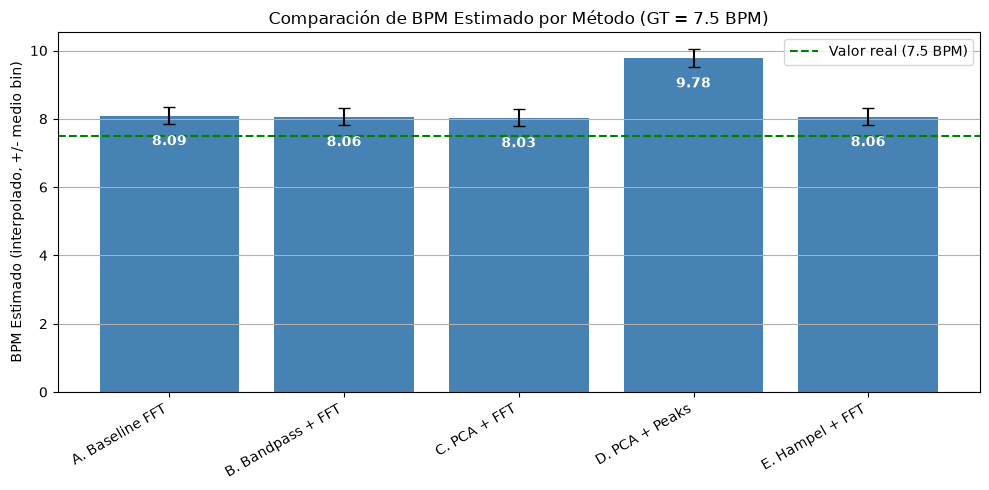

In [28]:
plt.figure(figsize=(10, 5))
bars = plt.bar(df_results['Method'], df_results['BPM (interpolated)*'], color='steelblue',
                yerr=half_bin_bpm, capsize=4)

# Traducción de los labels y el título
plt.ylabel('BPM Estimado (interpolado, +/- medio bin)')
plt.title('Comparación de BPM Estimado por Método (GT = 7.5 BPM)')
plt.axhline(GT_BPM, color='green', linestyle='--', label=f'Valor real ({GT_BPM} BPM)')

plt.xticks(rotation=30, ha='right')
plt.legend()
plt.grid(True, axis='y')

# Modificación para poner los números debajo de la barra de error
for bar, val in zip(bars, df_results['BPM (interpolated)*']):
    # Se resta el error y un pequeño margen para que quede por debajo
    # Se añade va='top' y color='white' para mejor legibilidad dentro de la barra
    plt.text(bar.get_x() + bar.get_width()/2, val - half_bin_bpm - 0.3, 
             f"{val:.2f}", ha='center', va='top', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('fig_comparacion_bpm.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Limitaciones (para Discusión / Conclusiones del paper)

Texto sugerido para reforzar la sección de limitaciones, incorporando las
observaciones de los Revisores 1, 2 y 3:

> Los resultados provienen de una única captura de ~2 minutos con un solo sujeto y
> una geometría fija (90 cm), por lo que ninguno de los porcentajes de error
> reportados tiene una medida de variabilidad o intervalo de confianza asociado. El
> ground truth (7.5 BPM) se infiere de la adherencia al protocolo de respiración
> controlada, no de un sensor de referencia independiente (p. ej. banda de esfuerzo
> torácico), lo que introduce una fuente de error no cuantificada si el sujeto no
> mantuvo el ritmo exactamente. Además, la convergencia exacta observada entre los
> métodos A, B, C y E (8.03–8.09 BPM) debe interpretarse con cautela: el ancho de
> bin de la FFT en esta captura (0.502 BPM) es comparable a las diferencias entre
> estimaciones, por lo que la convergencia refleja en parte la resolución espectral
> disponible y no puede tomarse como evidencia definitiva de acuerdo metodológico
> independiente. Trabajo futuro debe extender las pruebas a ≥3 sujetos, ≥3
> frecuencias respiratorias (incluyendo el rango de reposo 12–20 BPM), ≥2 distancias
> entre nodos y ≥5 repeticiones por condición, e incorporar una banda de esfuerzo
> respiratorio comercial como referencia independiente de ground truth, reportando
> MAE, RMSE, gráficos de Bland-Altman e intervalos de confianza.
